In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def euler(f, t0, x0, h, N):
    t = np.linspace(t0, t0+N*h, N+1)
    x = np.zeros(N+1); x[0] = x0
    for i in range(N):
        x[i+1] = x[i] + h*f(t[i], x[i])
    return t, x

def rk4(f, t0, x0, h, N):
    t = np.linspace(t0, t0+N*h, N+1)
    x = np.zeros(N+1); x[0] = x0
    for i in range(N):
        k1 = f(t[i], x[i])
        k2 = f(t[i]+h/2, x[i]+h/2*k1)
        k3 = f(t[i]+h/2, x[i]+h/2*k2)
        k4 = f(t[i]+h, x[i]+h*k3)
        x[i+1] = x[i] + h/6*(k1+2*k2+2*k3+k4)
    return t, x


steps = [0.4, 0.2, 0.1, 0.05]

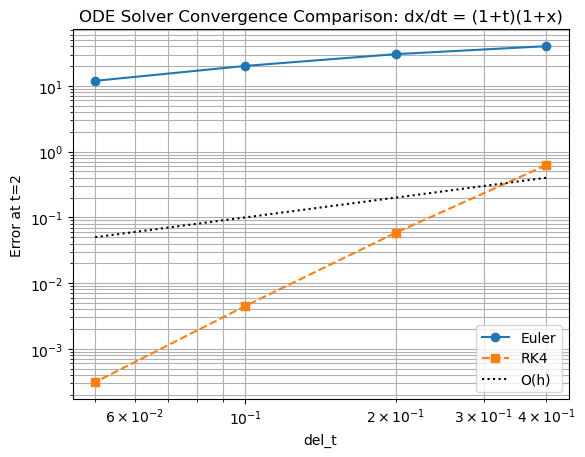

In [3]:
def f1(t, x):
    return (1+t)*(1+x)
    
true1 = lambda t: np.exp(t + t**2/2)-1  # true solution to x' = (1+t)(1+x)
err_euler_1, err_rk4_1 = [], []

for h in steps:
    N = int(2/h)
    t_1, xe_1 = euler(f1, 0, 0, h, N)  # initial condition: (x(t), t) = (0, 0)
    _, xr_1 = rk4(f1, 0, 0, h, N)
    err_euler_1.append(abs(xe_1[-1] - true1(2)))
    err_rk4_1.append(abs(xr_1[-1] - true1(2)))

plt.loglog(steps, err_euler_1, 'o-', label='Euler')
plt.loglog(steps, err_rk4_1, 's--', label='RK4')
plt.loglog(steps, steps, 'k:', label='O(h)')
plt.legend(); plt.xlabel('del_t'); plt.ylabel('Error at t=2'); plt.title('ODE Solver Convergence Comparison: dx/dt = (1+t)(1+x)'); plt.grid(True, which='both')
plt.show()

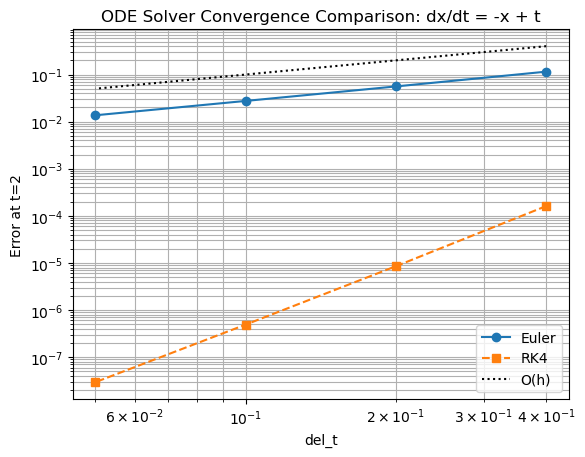

In [5]:
def f2(t, x):
    return -x + t

true2 = lambda t: t - 1 + 2*np.exp(-t)  # true solution to x' = -x + t
err_euler_2, err_rk4_2 = [], []

for h in steps:
    N = int(2/h)
    t_2, xe_2 = euler(f2, 0, 1, h, N)  # initial condition (x(t), t) = (1, 0)
    _, xr_2 = rk4(f2, 0, 1, h, N)
    err_euler_2.append(abs(xe_2[-1] - true2(2)))
    err_rk4_2.append(abs(xr_2[-1] - true2(2)))

plt.loglog(steps, err_euler_2, 'o-', label='Euler')
plt.loglog(steps, err_rk4_2, 's--', label='RK4')
plt.loglog(steps, steps, 'k:', label='O(h)')
plt.legend(); plt.xlabel('del_t'); plt.ylabel('Error at t=2'); plt.title('ODE Solver Convergence Comparison: dx/dt = -x + t'); plt.grid(True, which='both')
plt.show()

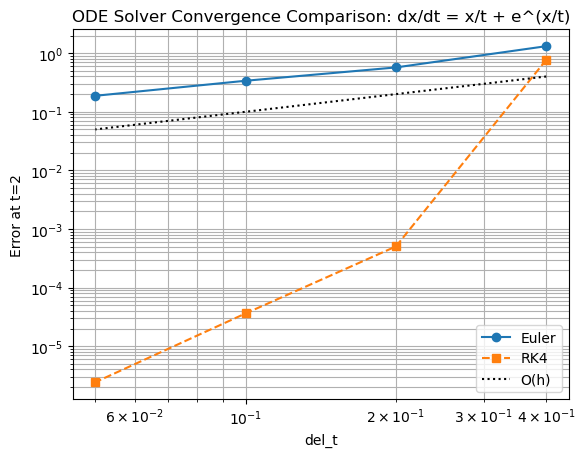

In [4]:
def f3(t, x):
    return x/t + np.exp(x/t)

true3 = lambda t: -t*np.log(-np.log(t) + 1)
err_euler_3, err_rk4_3 = [], []

for h in steps:
    N = int(1/h)
    t_3, xe_3 = euler(f3, 1, 0, h, N)  
    _, xr_3 = rk4(f3, 1, 0, h, N)
    err_euler_3.append(abs(xe_3[-1] - true3(2)))
    err_rk4_3.append(abs(xr_3[-1] - true3(2)))

plt.loglog(steps, err_euler_3, 'o-', label='Euler')
plt.loglog(steps, err_rk4_3, 's--', label='RK4')
plt.loglog(steps, steps, 'k:', label='O(h)')
plt.legend(); plt.xlabel('del_t'); plt.ylabel('Error at t=2') 
plt.title('ODE Solver Convergence Comparison: dx/dt = x/t + e^(x/t)'); plt.grid(True, which='both')
plt.show()